# Assignment 2: Drink Classification (Cola / Fanta / Pepsi), Level-Up with SOTA CV + Demo
Продолжение A1. Что добавляем:
- **SOTA-модель:** DINOv2 (self-supervised ViT, Meta, 2023): эмбеддинги + linear probe + nearest-neighbours.
- **Синтетика:** SDXL-Turbo генерирует сложные варианты (подсветка, перекрытие, фон) для редких/трудных условий. Всё помечается как synthetic.
- **Сравнение с A1:** ResNet18 (ваш лучший результат из A1) vs DINOv2.
- **Метрики:** Accuracy, Macro-F1, (Top-5 при >5 классов), retrieval P@k, латентность.
- **Абляция:** с синтетикой / без синтетики.
- **Объяснимость:** Grad-CAM (ResNet18) + галерея ближайших соседей (DINOv2).
- **Демо:** Gradio-приложение (загрузка / веб-камера → класс → объяснение → "Generate similar").

**Как пользоваться:** `Runtime → Change runtime type → T4 GPU`, затем запускай ячейки сверху вниз.

## 0. Setup

In [ ]:
!pip -q install transformers gradio diffusers accelerate roboflow scikit-learn

In [ ]:
import os, glob, random, time, shutil, zipfile, platform, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch, torch.nn as nn
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
ENV = f"{torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'} | torch {torch.__version__} | Python {platform.python_version()}"
print('Device:', ENV)

DATA_DIR = '/content/dataset'
SYN_DIR = '/content/synthetic'
IMG_SIZE, BATCH = 224, 32
IMG_EXT = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')
results = []   # сюда складываем метрики для итоговой таблицы

Device: Tesla T4 | torch 2.11.0+cu130 | Python 3.13.16


In [ ]:
shutil.unpack_archive('/content/dataset.zip', DATA_DIR)
if os.path.exists('/content/synthetic.zip'): shutil.unpack_archive('/content/synthetic.zip', SYN_DIR)
print(os.listdir(DATA_DIR))

['cola', 'fanta', 'water_bottle', 'pepsi']


## 1. Данные
Выбери **один** вариант (A, B или C) и запусти только его.

- **A:** твой zip с папками `cola/`, `fanta/`, `pepsi/`.
- **B:** готовый датасет с Roboflow Universe. На странице датасета: *Download Dataset → format **Folder Structure** → show download code*. Вставь код ниже и поставь `location=DATA_DIR`.
- **C:** видео → кадры, как в A1 (положи видео в `/content/videos/<класс>/`).

In [ ]:
# ---- Вариант A: zip ----
from google.colab import files
up = files.upload()
name = list(up.keys())[0]
os.makedirs(DATA_DIR, exist_ok=True)
with zipfile.ZipFile(name) as z:
    z.extractall(DATA_DIR)
print(os.listdir(DATA_DIR))

In [ ]:
# ---- Вариант B: Roboflow ----
# Вставь сюда сниппет с сайта Roboflow. Он выглядит примерно так:
# from roboflow import Roboflow
# rf = Roboflow(api_key="YOUR_KEY")
# project = rf.workspace("...").project("...")
# dataset = project.version(1).download("folder", location=DATA_DIR)
# Для нескольких датасетов качай каждый в свою папку, потом копируй классы в DATA_DIR.

In [ ]:
# ---- Вариант C: видео -> кадры (как в A1) ----
import cv2
VIDEO_DIR, EVERY_N = '/content/videos', 10
for cls in sorted(os.listdir(VIDEO_DIR)):
    out = os.path.join(DATA_DIR, cls); os.makedirs(out, exist_ok=True)
    count = 0
    for vf in glob.glob(os.path.join(VIDEO_DIR, cls, '*')):
        cap = cv2.VideoCapture(vf); i = 0
        vid_id = os.path.splitext(os.path.basename(vf))[0]
        while True:
            ok, frame = cap.read()
            if not ok: break
            if i % EVERY_N == 0:
                cv2.imwrite(os.path.join(out, f'{vid_id}_{i:05d}.jpg'), frame); count += 1
            i += 1
        cap.release()
    print(cls, count, 'frames')

In [ ]:
# vavriant D

import yaml, glob, os, zipfile
from PIL import Image

RAW = '/content/raw'
zip_path = glob.glob('/Bottle_identification.v6i.yolov8.zip')[0]          # твой скачанный zip
zipfile.ZipFile(zip_path).extractall(RAW)

cfg = yaml.safe_load(open(f'{RAW}/data.yaml'))
names = cfg['names']
if isinstance(names, dict): names = [names[k] for k in sorted(names)]
print('classes:', names)

n = 0
for split in ('train', 'valid', 'test'):
    for lf in glob.glob(f'{RAW}/{split}/labels/*.txt'):
        stem = os.path.splitext(os.path.basename(lf))[0]
        found = glob.glob(f'{RAW}/{split}/images/{stem}.*')
        if not found: continue
        im = Image.open(found[0]).convert('RGB'); W, H = im.size
        for k, line in enumerate(open(lf)):
            p = line.split()
            if len(p) != 5: continue
            c = int(p[0]); cx, cy, w, h = [float(v) for v in p[1:]]
            pad = 0.10
            x0 = max(0, int((cx - w/2 - pad*w) * W)); x1 = min(W, int((cx + w/2 + pad*w) * W))
            y0 = max(0, int((cy - h/2 - pad*h) * H)); y1 = min(H, int((cy + h/2 + pad*h) * H))
            if x1 - x0 < 32 or y1 - y0 < 32: continue      # слишком мелкие рамки пропускаем
            out = f'{DATA_DIR}/{names[c]}'; os.makedirs(out, exist_ok=True)
            im.crop((x0, y0, x1, y1)).save(f'{out}/{split}_{stem}_{k}.jpg'); n += 1
print('crops saved:', n)


classes: ['cola', 'fanta', 'pepsi', 'water_bottle']
crops saved: 492


### Структура, классы, split 70/15/15
> ⚠️ Если данные из видео (вариант C), соседние кадры почти одинаковы. При случайном split они попадут и в train, и в test, и точность будет завышена. В отчёте это нужно упомянуть, а лучше снимать отдельные видео для test.

{'cola': 190, 'fanta': 79, 'pepsi': 156, 'water_bottle': 86} | total = 511 | train/val/test = 357 77 77


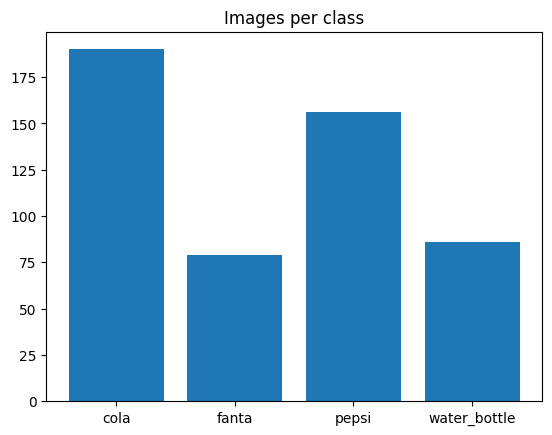

In [ ]:
def merge_split_dirs(root):
    # Roboflow: root/train|valid|test/<class>/img -> root/<class>/img
    for s in ('train', 'valid', 'val', 'test'):
        sp = os.path.join(root, s)
        if not os.path.isdir(sp): continue
        for cls in os.listdir(sp):
            src = os.path.join(sp, cls)
            if not os.path.isdir(src): continue
            dst = os.path.join(root, cls); os.makedirs(dst, exist_ok=True)
            for f in os.listdir(src):
                shutil.move(os.path.join(src, f), os.path.join(dst, f'{s}_{f}'))
        shutil.rmtree(sp)

def find_class_root(root):
    for dp, dirs, _ in os.walk(root):
        good = [d for d in dirs if any(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(dp, d)))]
        if len(good) >= 2: return dp
    raise RuntimeError('Не нашёл папки классов с картинками')

merge_split_dirs(DATA_DIR)
CLASS_ROOT = find_class_root(DATA_DIR)
class_names = sorted(d for d in os.listdir(CLASS_ROOT) if os.path.isdir(os.path.join(CLASS_ROOT, d)))

paths, labels = [], []
for i, c in enumerate(class_names):
    for f in sorted(glob.glob(f'{CLASS_ROOT}/{c}/*')):
        if f.lower().endswith(IMG_EXT): paths.append(f); labels.append(i)
paths, labels = np.array(paths), np.array(labels)

idx = np.arange(len(paths))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=labels[tmp], random_state=SEED)
train_paths, train_y = paths[tr], labels[tr]
val_paths, val_y = paths[va], labels[va]
test_paths, test_y = paths[te], labels[te]

counts = {c: int((labels == i).sum()) for i, c in enumerate(class_names)}
print(counts, '| total =', len(paths), '| train/val/test =', len(tr), len(va), len(te))
plt.bar(counts.keys(), counts.values()); plt.title('Images per class'); plt.show()

In [ ]:
import os
print('exists:', os.path.exists('/content/dataset'))
if os.path.exists('/content/dataset'):
    for c in sorted(os.listdir('/content/dataset')):
        p = os.path.join('/content/dataset', c)
        print(c, len(os.listdir(p)) if os.path.isdir(p) else 'file')

exists: True
cola 190
fanta 79
pepsi 156
water_bottle 86


## 2. Preprocessing / augmentation (как в A1) и loaders

In [ ]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15), transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize(mean, std)])

class DS(torch.utils.data.Dataset):
    def __init__(self, p, y, tf): self.p, self.y, self.tf = list(p), list(y), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert('RGB')), int(self.y[i])

train_loader = torch.utils.data.DataLoader(DS(train_paths, train_y, train_tf), batch_size=BATCH, shuffle=True, num_workers=2)
val_loader = torch.utils.data.DataLoader(DS(val_paths, val_y, eval_tf), batch_size=BATCH, num_workers=2)
test_loader = torch.utils.data.DataLoader(DS(test_paths, test_y, eval_tf), batch_size=BATCH, num_workers=2)

## 3. Утилиты обучения и оценки

In [ ]:
def train_model(model, epochs, lr, name):
    model = model.to(device)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_acc, best_state = -1, None
    for ep in range(epochs):
        model.train(); tl = tc = n = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); out = model(x); loss = loss_fn(out, y); loss.backward(); opt.step()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        model.eval(); vl = vc = vn = 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device); out = model(x)
                vl += loss_fn(out, y).item() * len(y); vc += (out.argmax(1) == y).sum().item(); vn += len(y)
        hist['train_loss'].append(tl / n); hist['val_loss'].append(vl / vn)
        hist['train_acc'].append(tc / n); hist['val_acc'].append(vc / vn)
        if vc / vn > best_acc: best_acc = vc / vn; best_state = {k: v.clone() for k, v in model.state_dict().items()}
        print(f'[{name}] epoch {ep+1}/{epochs} train_acc={tc/n:.3f} val_acc={vc/vn:.3f} val_loss={vl/vn:.3f}')
    model.load_state_dict(best_state)
    return model, hist

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(h['train_loss'], label='train'); ax[0].plot(h['val_loss'], label='val'); ax[0].set_title(title + ' loss'); ax[0].legend()
    ax[1].plot(h['train_acc'], label='train'); ax[1].plot(h['val_acc'], label='val'); ax[1].set_title(title + ' accuracy'); ax[1].legend()
    plt.tight_layout(); plt.savefig(f'/content/curves_{title.replace(" ", "_")}.png', dpi=150); plt.show()

@torch.no_grad()
def predict_proba(model, loader):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        ps.append(torch.softmax(model(x.to(device)), 1).cpu()); ys += y.tolist()
    return np.array(ys), torch.cat(ps).numpy()

def report(name, y, probs):
    p = probs.argmax(1)
    row = {'model': name, 'accuracy': accuracy_score(y, p), 'macro_f1': f1_score(y, p, average='macro')}
    if len(class_names) > 5:
        row['top5'] = float(np.mean([y[i] in np.argsort(-probs[i])[:5] for i in range(len(y))]))
    print(classification_report(y, p, target_names=class_names, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y, p), display_labels=class_names).plot(cmap='Blues')
    plt.title(name); plt.savefig(f'/content/cm_{name.replace(" ", "_")}.png', dpi=150); plt.show()
    results.append(row); return row

## 4. A1 baseline: ResNet18 (transfer learning)
Это ваш лучший результат из A1. Скомпоновано так же: 8 эпох, lr=1e-4.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s]


[ResNet18] epoch 1/8 train_acc=0.745 val_acc=0.948 val_loss=0.228
[ResNet18] epoch 2/8 train_acc=0.983 val_acc=0.961 val_loss=0.061
[ResNet18] epoch 3/8 train_acc=0.992 val_acc=1.000 val_loss=0.027
[ResNet18] epoch 4/8 train_acc=0.994 val_acc=0.987 val_loss=0.033
[ResNet18] epoch 5/8 train_acc=0.992 val_acc=1.000 val_loss=0.012
[ResNet18] epoch 6/8 train_acc=1.000 val_acc=1.000 val_loss=0.018
[ResNet18] epoch 7/8 train_acc=1.000 val_acc=1.000 val_loss=0.035
[ResNet18] epoch 8/8 train_acc=1.000 val_acc=1.000 val_loss=0.022


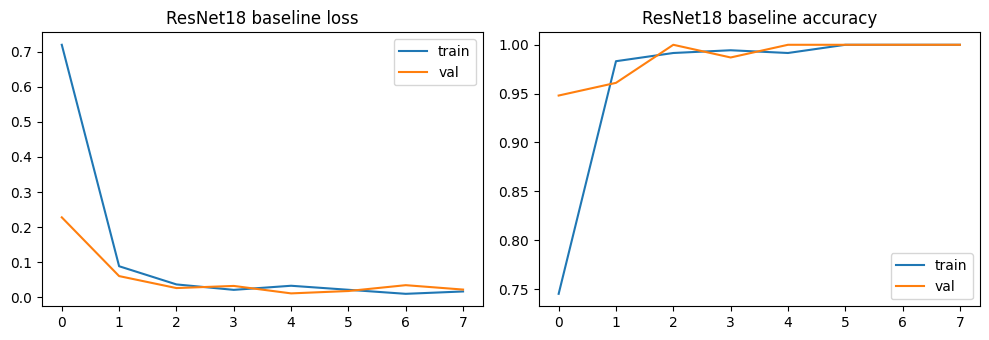

              precision    recall  f1-score   support

        cola      1.000     0.931     0.964        29
       fanta      0.857     1.000     0.923        12
       pepsi      1.000     1.000     1.000        23
water_bottle      1.000     1.000     1.000        13

    accuracy                          0.974        77
   macro avg      0.964     0.983     0.972        77
weighted avg      0.978     0.974     0.975        77



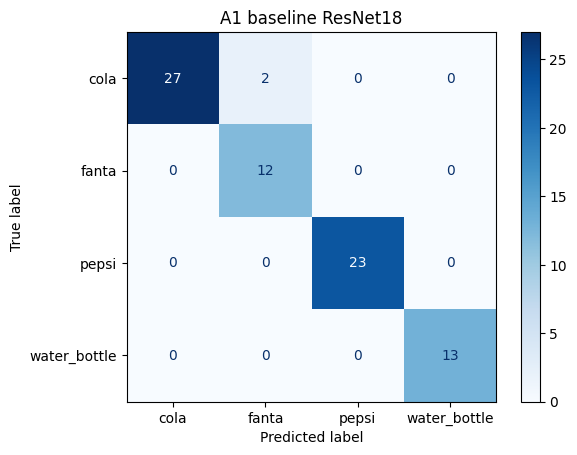

{'model': 'A1 baseline ResNet18',
 'accuracy': 0.974025974025974,
 'macro_f1': 0.9718406593406593}

In [ ]:
baseline = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
baseline.fc = nn.Linear(baseline.fc.in_features, len(class_names))
baseline, h_base = train_model(baseline, epochs=8, lr=1e-4, name='ResNet18')
plot_history(h_base, 'ResNet18 baseline')
y_te, probs_base = predict_proba(baseline, test_loader)
report('A1 baseline ResNet18', y_te, probs_base)

## 5. SOTA: DINOv2
**Что это.** DINOv2 (Oquab et al., Meta AI, 2023) это Vision Transformer, обученный *без меток* (self-supervised) на ~142 млн отобранных изображений. Его эмбеддинги хорошо работают «как есть»: достаточно простого линейного классификатора поверх замороженной модели, а поиск похожих изображений делается по косинусному расстоянию.

**Почему это помогает нашей теме.** Cola и Pepsi отличаются мелкими деталями (логотип, оттенок этикетки). ImageNet-ResNet18 может опереться на фон и форму бутылки, а DINOv2 даёт более устойчивые признаки. К тому же эмбеддинги бесплатно дают retrieval (галерея похожих фото) для демо.

> В отчёте добавьте 1 страницу: схема (картинка → ViT → CLS-эмбеддинг → Logistic Regression / kNN) + ссылка на статью и на источник, который вы взяли как объяснение (например, страница Neurohive, если она есть).

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

(357, 768) (77, 768)
val acc: 0.987012987012987
              precision    recall  f1-score   support

        cola      0.963     0.897     0.929        29
       fanta      0.786     0.917     0.846        12
       pepsi      1.000     1.000     1.000        23
water_bottle      1.000     1.000     1.000        13

    accuracy                          0.948        77
   macro avg      0.937     0.953     0.944        77
weighted avg      0.953     0.948     0.949        77



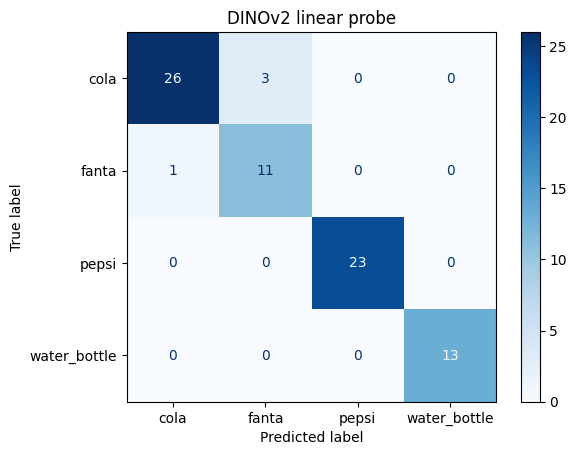

{'model': 'DINOv2 linear probe',
 'accuracy': 0.948051948051948,
 'macro_f1': 0.9436813186813187}

In [ ]:
from transformers import AutoModel
DINO_NAME = 'facebook/dinov2-base'      # для скорости можно 'facebook/dinov2-small'
dino = AutoModel.from_pretrained(DINO_NAME).to(device).eval()

@torch.no_grad()
def embed_tensor(x):
    f = dino(pixel_values=x.to(device)).pooler_output    # CLS token после LayerNorm
    return nn.functional.normalize(f, dim=1).cpu().numpy()

def embed_pil(imgs):
    return embed_tensor(torch.stack([eval_tf(im.convert('RGB')) for im in imgs]))

def embed_paths(plist, bs=64):
    out = []
    for i in range(0, len(plist), bs):
        out.append(embed_pil([Image.open(p) for p in plist[i:i+bs]]))
    return np.concatenate(out)

F_train, F_val, F_test = embed_paths(train_paths), embed_paths(val_paths), embed_paths(test_paths)
print(F_train.shape, F_test.shape)

clf = LogisticRegression(max_iter=3000, C=10).fit(F_train, train_y)
print('val acc:', clf.score(F_val, val_y))
probs_dino = clf.predict_proba(F_test)
report('DINOv2 linear probe', test_y, probs_dino)

In [ ]:
# Retrieval: precision@k среди ближайших train-соседей (косинус; эмбеддинги уже нормированы)
def precision_at_k(F_query, y_query, F_gallery, y_gallery, k=5):
    sims = F_query @ F_gallery.T
    top = np.argsort(-sims, axis=1)[:, :k]
    return float((y_gallery[top] == y_query[:, None]).mean())

for k in (1, 5, 10):
    print(f'retrieval P@{k}:', round(precision_at_k(F_test, test_y, F_train, train_y, k), 3))
results[-1]['retrieval_P@5'] = precision_at_k(F_test, test_y, F_train, train_y, 5)

retrieval P@1: 0.948
retrieval P@5: 0.925
retrieval P@10: 0.883


**Про Top-5.** При 3 классах Top-5 всегда равен 100% и ничего не показывает. Ячейка выше считает его автоматически, только если классов больше 5. Если расширите датасет (sprite, water, 7up и т.д.), метрика появится в таблице.

## 6. Латентность

In [ ]:
def bench(fn, n=50, warm=5):
    for _ in range(warm): fn()
    if device == 'cuda': torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(n): fn()
    if device == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t) / n * 1000

sample = Image.open(test_paths[0]).convert('RGB')
baseline.eval()
def run_resnet():
    with torch.no_grad(): baseline(eval_tf(sample).unsqueeze(0).to(device))
def run_dino(): clf.predict_proba(embed_pil([sample]))

lat = {'A1 baseline ResNet18': bench(run_resnet), 'DINOv2 linear probe': bench(run_dino)}
for r in results:
    if r['model'] in lat: r['latency_ms'] = lat[r['model']]
print({k: f'{v:.1f} ms' for k, v in lat.items()}, '|', ENV)

{'A1 baseline ResNet18': '49.7 ms', 'DINOv2 linear probe': '111.0 ms'} | Tesla T4 | torch 2.11.0+cu130 | Python 3.13.16


## 7. Синтетические данные (SDXL-Turbo) и абляция
Генерируем сложные варианты (подсветка, перекрытие, фон, смаз). Синтетика идёт **только в train**. val/test остаются реальными, иначе сравнение нечестное.

> ⚠️ Генераторы часто искажают логотипы. Просмотри картинки ниже и удали плохие, это и есть шаг «pick best» из задания. Влияние качества синтетики и покажет абляция.

In [ ]:
from diffusers import AutoPipelineForText2Image
assert device == 'cuda', 'Для генерации нужен GPU (T4)'
t2i = AutoPipelineForText2Image.from_pretrained('stabilityai/sdxl-turbo', torch_dtype=torch.float16, variant='fp16').to('cuda')

SUBJECT = {'cola': 'a bottle of Coca-Cola', 'fanta': 'a bottle of Fanta orange soda', 'pepsi': 'a bottle of Pepsi','water_bottle': 'a plastic bottle of drinking water'}
CONDITIONS = ['in strong backlight', 'in dim indoor light', 'on a cluttered kitchen table', 'held in a hand',
              'on a fridge shelf', 'outdoors on a bench', 'partially hidden behind another object', 'slightly motion blurred']
N_PER_CLASS = 40

def make_prompt(cls, cond):
    subj = SUBJECT.get(cls, f'a bottle of {cls} soft drink')
    return f'a smartphone photo of {subj} {cond}, realistic, label clearly visible'

g = torch.Generator('cuda').manual_seed(SEED)
for cls in class_names:
    os.makedirs(f'{SYN_DIR}/{cls}', exist_ok=True)
    for k in range(N_PER_CLASS):
        img = t2i(prompt=make_prompt(cls, CONDITIONS[k % len(CONDITIONS)]), num_inference_steps=1, guidance_scale=0.0, generator=g).images[0]
        img.save(f'{SYN_DIR}/{cls}/syn_{k:03d}.jpg')

fig, axes = plt.subplots(len(class_names), 8, figsize=(20, 2.6 * len(class_names)))
for r, cls in enumerate(class_names):
    for c in range(8):
        axes[r, c].imshow(Image.open(f'{SYN_DIR}/{cls}/syn_{c:03d}.jpg')); axes[r, c].axis('off')
    axes[r, 0].set_title(cls, loc='left')
plt.tight_layout(); plt.show()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

... (107 outputs left out)

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/1 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


KeyboardInterrupt: 

synthetic: 160 | share of training set = 30.9%
              precision    recall  f1-score   support

        cola      0.963     0.897     0.929        29
       fanta      0.786     0.917     0.846        12
       pepsi      1.000     1.000     1.000        23
water_bottle      1.000     1.000     1.000        13

    accuracy                          0.948        77
   macro avg      0.937     0.953     0.944        77
weighted avg      0.953     0.948     0.949        77



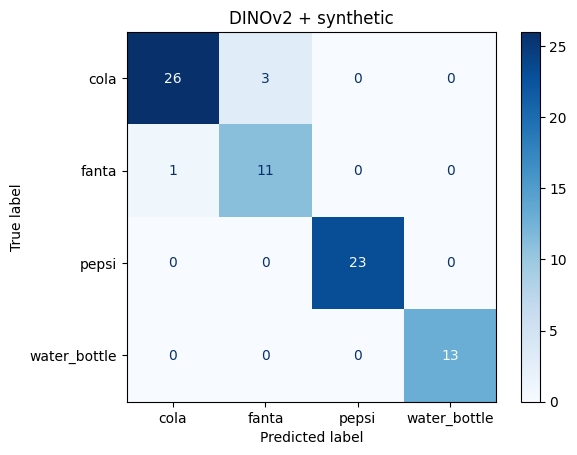

Δ macro-F1 vs real-only: 0.0


In [ ]:
# Удали плохие файлы вручную (панель файлов слева) и запускай эту ячейку, она берёт то, что осталось.
syn_paths, syn_y = [], []
for i, c in enumerate(class_names):
    for f in sorted(glob.glob(f'{SYN_DIR}/{c}/*.jpg')): syn_paths.append(f); syn_y.append(i)
syn_y = np.array(syn_y)
F_syn = embed_paths(syn_paths)

share = len(syn_paths) / (len(train_paths) + len(syn_paths))
print(f'synthetic: {len(syn_paths)} | share of training set = {share:.1%}')

clf_syn = LogisticRegression(max_iter=3000, C=10).fit(np.vstack([F_train, F_syn]), np.concatenate([train_y, syn_y]))
probs_syn = clf_syn.predict_proba(F_test)
report('DINOv2 + synthetic', test_y, probs_syn)
results[-1]['retrieval_P@5'] = None
print('Δ macro-F1 vs real-only:', round(results[-1]['macro_f1'] - [r for r in results if r['model'] == 'DINOv2 linear probe'][0]['macro_f1'], 4))

In [ ]:
for r in results:
    if r['model'] == 'DINOv2 + synthetic':
        r['model'] = 'DINOv2 + synthetic (unfiltered)'
print([r['model'] for r in results])

['A1 baseline ResNet18', 'DINOv2 linear probe', 'DINOv2 + synthetic (unfiltered)']


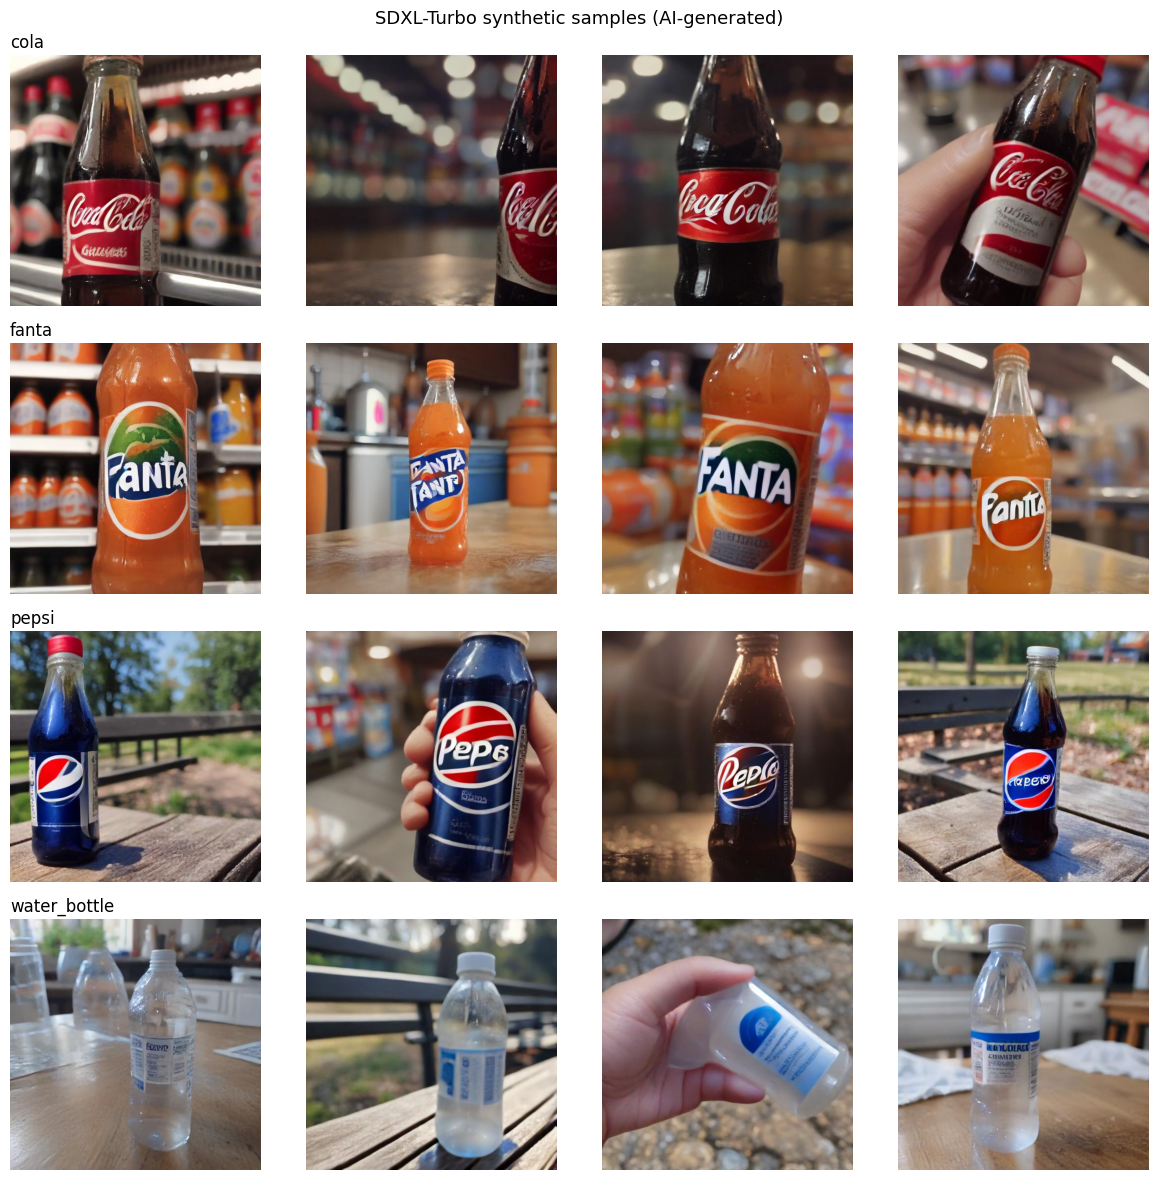

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import glob, random
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

N_PER_CLASS = 4
random.seed(7)          # поменяйте число, чтобы выбрать другие картинки

fig, axes = plt.subplots(len(class_names), N_PER_CLASS, figsize=(3 * N_PER_CLASS, 3 * len(class_names)))
for r, cls in enumerate(class_names):
    imgs = sorted(glob.glob(f'{SYN_DIR}/{cls}/*.jpg'))
    for c, p in enumerate(random.sample(imgs, min(N_PER_CLASS, len(imgs)))):
        axes[r, c].imshow(Image.open(p).convert('RGB'))
        axes[r, c].axis('off')
    axes[r, 0].set_title(cls, loc='left', fontsize=12)
plt.suptitle('SDXL-Turbo synthetic samples (AI-generated)', fontsize=13)
plt.tight_layout()
plt.savefig('/content/fig1_synthetic_samples.png', dpi=150)
plt.show()
files.download('/content/fig1_synthetic_samples.png')

## 8. Объяснимость: Grad-CAM (ResNet18) и ближайшие соседи (DINOv2)

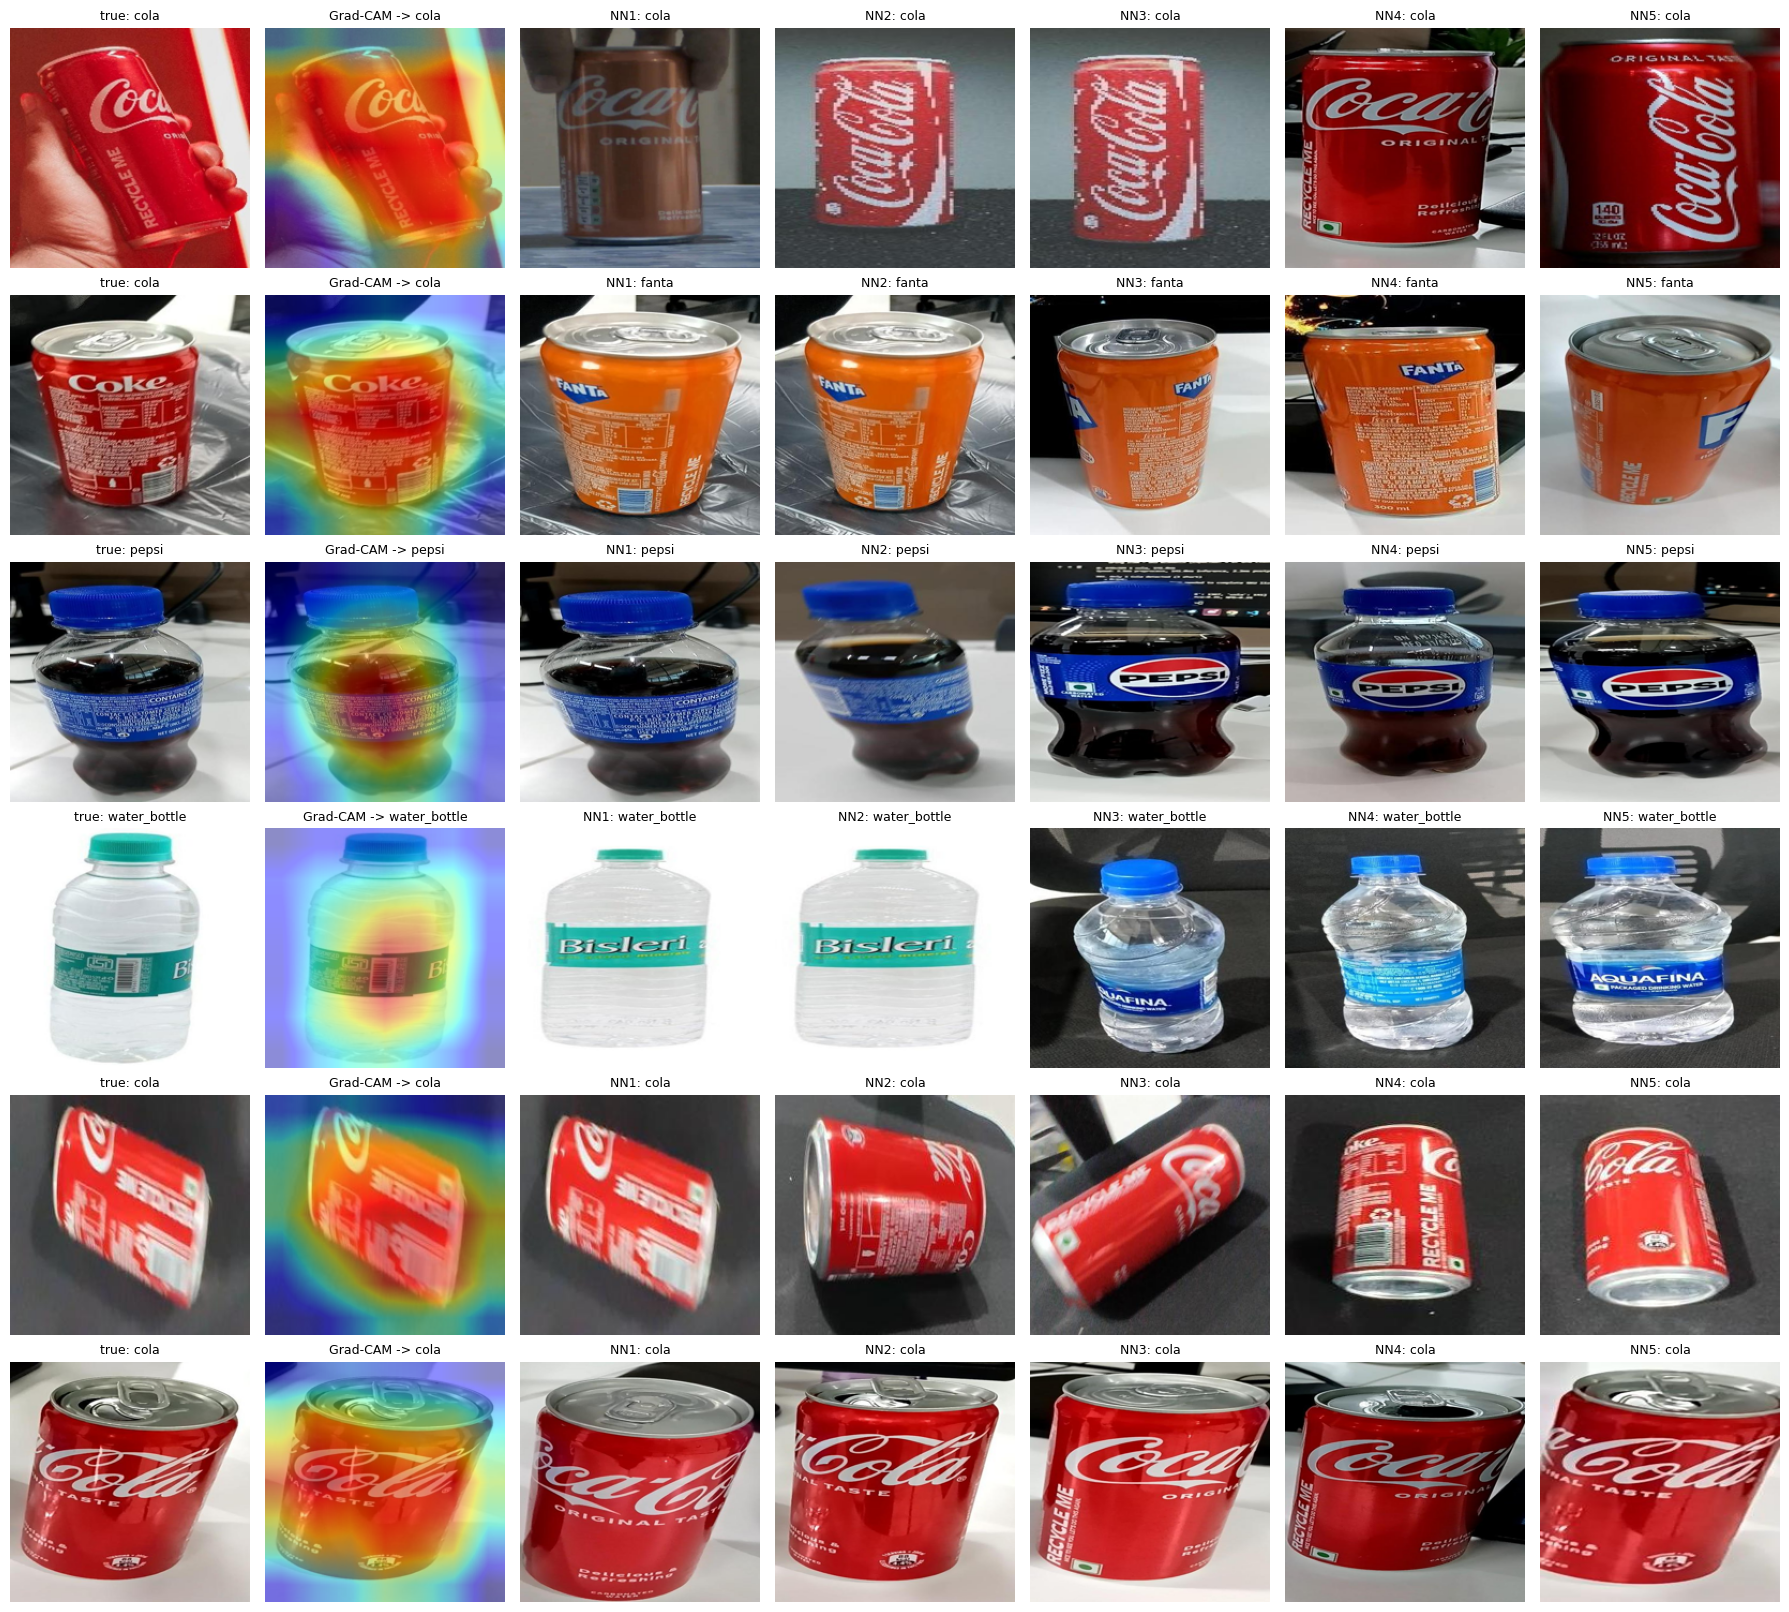

In [ ]:
inv_mean, inv_std = torch.tensor(mean).view(3, 1, 1), torch.tensor(std).view(3, 1, 1)
def to_img(x): return (x.cpu() * inv_std + inv_mean).clamp(0, 1).permute(1, 2, 0).numpy()

def gradcam(model, x, target=None):
    store = {}
    def fwd_hook(m, i, o):
        store['a'] = o
        o.register_hook(lambda g: store.__setitem__('g', g))
    h = model.layer4.register_forward_hook(fwd_hook)
    model.eval(); model.zero_grad()
    out = model(x)
    c = int(out.argmax(1)) if target is None else target
    out[0, c].backward()
    h.remove()
    w = store['g'].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * store['a']).sum(1))[0].detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    cam = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)) / 255.0
    return cam, c

def overlay(img01, cam, alpha=0.45):
    heat = plt.cm.jet(cam)[..., :3]
    return ((1 - alpha) * img01 + alpha * heat).clip(0, 1)

def nearest(feat, k=5):
    sims = F_train @ feat
    return np.argsort(-sims)[:k]

# 6 случайных тестовых примеров: оригинал | Grad-CAM | 5 соседей
rng = np.random.RandomState(1)
pick = rng.choice(len(test_paths), 6, replace=False)
fig, axes = plt.subplots(len(pick), 7, figsize=(18, 2.7 * len(pick)))
for r, i in enumerate(pick):
    img = Image.open(test_paths[i]).convert('RGB')
    x = eval_tf(img).unsqueeze(0).to(device)
    cam, c = gradcam(baseline, x)
    axes[r, 0].imshow(img.resize((IMG_SIZE, IMG_SIZE))); axes[r, 0].set_title(f'true: {class_names[test_y[i]]}', fontsize=9)
    axes[r, 1].imshow(overlay(to_img(x[0]), cam)); axes[r, 1].set_title(f'Grad-CAM -> {class_names[c]}', fontsize=9)
    for k, j in enumerate(nearest(F_test[i])):
        axes[r, 2 + k].imshow(Image.open(train_paths[j]).convert('RGB').resize((IMG_SIZE, IMG_SIZE)))
        axes[r, 2 + k].set_title(f'NN{k+1}: {class_names[train_y[j]]}', fontsize=9)
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.savefig('/content/explainability.png', dpi=150); plt.show()

## 9. Демо-приложение (Gradio)
Загрузка фото или веб-камера → класс → Grad-CAM + ближайшие соседи + латентность. Кнопка **Generate similar** создаёт 4 синтетические картинки выбранного класса с водяным знаком.

**Этика и согласие:** изображения обрабатываются в памяти и не сохраняются. Не загружай фото людей без их согласия. Все сгенерированные картинки помечены водяным знаком `SYNTHETIC`.

In [ ]:
import gradio as gr

def watermark(img, text='SYNTHETIC / AI-GENERATED'):
    img = img.convert('RGB').copy(); d = ImageDraw.Draw(img)
    w, h = img.size
    d.rectangle([0, h - 28, w, h], fill=(0, 0, 0)); d.text((8, h - 22), text, fill=(255, 255, 255))
    return img

def analyse(img):
    if img is None: return None, None, None, 'Загрузи фото'
    img = img.convert('RGB')
    t0 = time.perf_counter()
    feat = embed_pil([img])[0]
    probs = clf.predict_proba(feat[None])[0]
    ms = (time.perf_counter() - t0) * 1000
    x = eval_tf(img).unsqueeze(0).to(device)
    cam, c = gradcam(baseline, x)
    cam_img = (overlay(to_img(x[0]), cam) * 255).astype(np.uint8)
    gal = [(Image.open(train_paths[j]).convert('RGB'), f'{class_names[train_y[j]]}') for j in nearest(feat)]
    info = f'**DINOv2 inference:** {ms:.0f} ms &nbsp;|&nbsp; **Env:** {ENV}'
    return {class_names[i]: float(p) for i, p in enumerate(probs)}, cam_img, gal, info

def generate_similar(cls):
    g2 = torch.Generator('cuda').manual_seed(random.randint(0, 10**6))
    conds = random.sample(CONDITIONS, 4)
    return [watermark(t2i(prompt=make_prompt(cls, cd), num_inference_steps=1, guidance_scale=0.0, generator=g2).images[0]) for cd in conds]

with gr.Blocks(title='Drink classifier') as demo:
    gr.Markdown('# Drink classifier: DINOv2 + Grad-CAM + nearest neighbours\nФото обрабатываются в памяти и не сохраняются.')
    with gr.Row():
        inp = gr.Image(type='pil', sources=['upload', 'webcam'], label='Фото напитка')
        with gr.Column():
            lab = gr.Label(num_top_classes=len(class_names), label='Prediction (DINOv2 linear probe)')
            info = gr.Markdown()
    btn = gr.Button('Analyse', variant='primary')
    with gr.Row():
        cam_out = gr.Image(label='Grad-CAM (ResNet18 baseline)')
        gal_out = gr.Gallery(label='Nearest neighbours from training set', columns=5, height=220)
    btn.click(analyse, inp, [lab, cam_out, gal_out, info])
    gr.Markdown('### Generate similar (synthetic data)')
    dd = gr.Dropdown(class_names, value=class_names[0], label='Class')
    gbtn = gr.Button('Generate 4 synthetic variants')
    syn_out = gr.Gallery(label='SYNTHETIC / AI-generated', columns=4, height=260)
    gbtn.click(generate_similar, dd, syn_out)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8e6f80c4149ce16f74.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


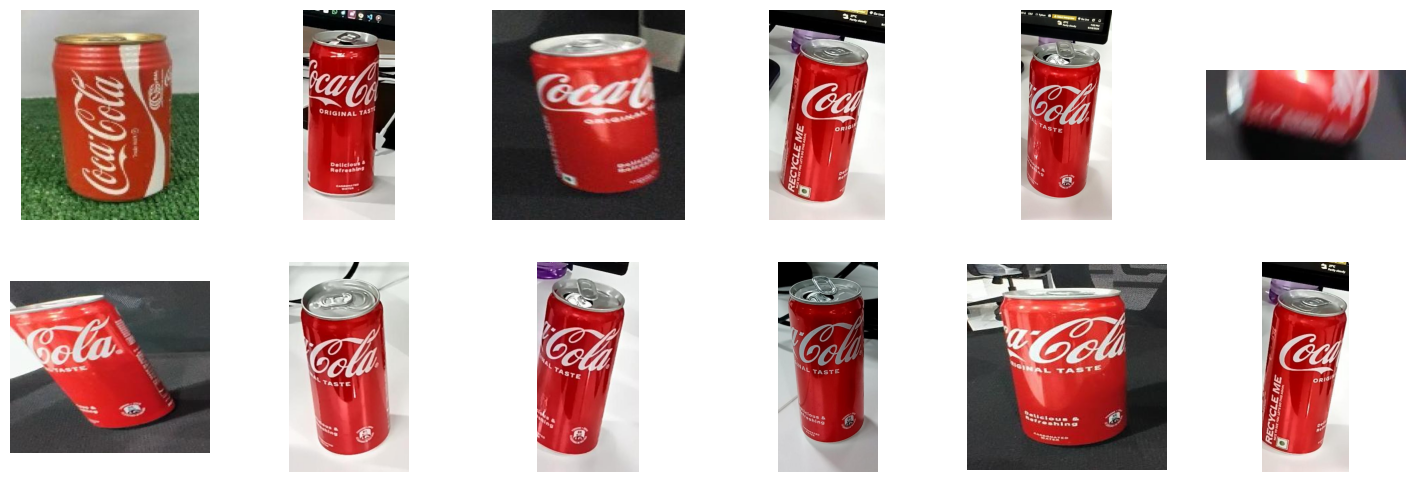

In [ ]:
cola_i = class_names.index('cola')
cola_imgs = [p for p, y in zip(train_paths, train_y) if y == cola_i]
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for a, p in zip(axes.ravel(), random.sample(cola_imgs, 12)):
    a.imshow(Image.open(p)); a.axis('off')
plt.show()

## 10. Итоговая таблица

In [ ]:
df = pd.DataFrame(results).round(4)
display(df)
df.to_csv('/content/results.csv', index=False)

# Сохранить всё нужное для отчёта на Google Drive
from google.colab import drive
drive.mount('/content/drive')
out = '/content/drive/MyDrive/CV_A2'; os.makedirs(out, exist_ok=True)
for f in glob.glob('/content/*.png') + ['/content/results.csv']: shutil.copy(f, out)
torch.save(baseline.state_dict(), f'{out}/resnet18_baseline.pt')
import joblib; joblib.dump(clf, f'{out}/dino_linear_probe.joblib')
print('Saved to', out)

,model,accuracy,macro_f1,latency_ms,retrieval_P@5
0,A1 baseline ResNet18,0.9740,0.9718,49.7141,NaN
1,DINOv2 linear probe,0.9481,0.9437,111.0230,0.9247
2,DINOv2 + synthetic (unfiltered),0.9481,0.9437,NaN,NaN


ValueError: mount failed

## 11. Заметки для отчёта (6–8 стр.)
| Раздел | Откуда взять |
|---|---|
| Dataset update | шаг 1 (размер, баланс), шаг 7 (доля синтетики) |
| SOTA method | шаг 5 + схема + ссылка на статью DINOv2 и источник объяснения |
| Experiments | таблица шага 10, кривые `curves_*.png`, confusion matrices `cm_*.png` |
| Ablation | строки `DINOv2 linear probe` и `DINOv2 + synthetic` |
| Explainability | `explainability.png` |
| Latency / env | шаг 6 |
| Ethics | синтетика помечена, нет фото людей без согласия, логотипы брендов искажаются генератором, смещение датасета (один телефон, мало мест) |
| Reproducibility | версии из `ENV`, `SEED=42`, как запускать, где лежат веса |

In [ ]:
import joblib, json
ART = '/content/artifacts'
os.makedirs(f'{ART}/gallery', exist_ok=True); os.makedirs(f'{ART}/synthetic_samples', exist_ok=True)

joblib.dump(clf, f'{ART}/probe.joblib')
if 'clf_syn' in globals(): joblib.dump(clf_syn, f'{ART}/probe_synthetic.joblib')
torch.save(baseline.state_dict(), f'{ART}/resnet18.pt')
np.save(f'{ART}/F_train.npy', F_train); np.save(f'{ART}/train_y.npy', train_y)
json.dump({'class_names': class_names, 'dino': DINO_NAME}, open(f'{ART}/meta.json', 'w'))

for i, p in enumerate(train_paths):          # миниатюры для галереи соседей
    Image.open(p).convert('RGB').resize((224, 224)).save(f'{ART}/gallery/{i:04d}.jpg', quality=85)
for c in class_names:                        # примеры синтетики
    for k, f in enumerate(sorted(glob.glob(f'{SYN_DIR}/{c}/*.jpg'))[:8]):
        shutil.copy(f, f'{ART}/synthetic_samples/{c}_{k}.jpg')

pd.DataFrame(results).round(4).to_csv('/content/results.csv', index=False)
shutil.copy('/content/results.csv', ART)
shutil.make_archive('/content/artifacts', 'zip', ART)
from google.colab import files; files.download('/content/artifacts.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(len(results), os.path.exists('/content/dataset'))

3 True
